# Практика: KV-кэш → MQA → GQA → StreamingLLM
В Colab выполните ячейки по порядку. Можно выбрать T4 GPU; CPU тоже подходит. Внешние данные и веса не нужны.

Сначала сравните no cache / full cache у исходной MHA, затем изучите полную реализацию MQA (одна KV-голова для всех запросов). Выполните два упражнения: GQA (две головы запросов на одну KV-голову) и StreamingLLM. До выполнения TODO соответствующие эксперименты пропускаются.

**Статья:** [Efficient Streaming Language Models with Attention Sinks, ICLR 2024](https://arxiv.org/abs/2309.17453).
**Код авторов:** [mit-han-lab/streaming-llm](https://github.com/mit-han-lab/streaming-llm): `kv_cache.py` и `pos_shift/modify_llama.py`.

StreamingLLM удаляет середину истории: память ограничена, но удалённый текст больше недоступен.

## 1. Предоставленная модель
Обучим исходную маленькую модель с MHA (RMSNorm, RoPE, SwiGLU) на предложениях вроде `alice likes red .` и построим кривую потерь. Это не checkpoint Llama 2.

K/V имеют форму `[batch, KV heads, tokens, head_dim]`. Модель сохраняет **K до RoPE** и V. Позиции определяются внутри текущего кэша, что позволяет сдвигать их после удаления токенов.

In [1]:
"""Provided tiny model, copied into notebooks by build_notebooks.py."""
import math, time, random
import torch
from torch import nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(42)
rng = random.Random(42)
torch.set_num_threads(2)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__, 'device:', device)

def sync():
    if device.type == 'cuda':
        torch.cuda.synchronize()

def cache_bytes(cache):
    return sum(t.numel()*t.element_size() for k,v in (cache or []) for t in (k,v))

class RMSNorm(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(dim))
    def forward(self, x):
        return x*torch.rsqrt(x.square().mean(-1, keepdim=True)+1e-6)*self.weight

_rope_tables = {}

def rope(x, start_pos=0):
    d = x.shape[-1]
    end_pos = start_pos+x.shape[-2]
    key = (x.device,x.dtype,d)
    table = _rope_tables.get(key)
    if table is None or table[0].shape[0] < end_pos:
        size = max(4096,end_pos*2)
        # Constants may be created during inference and reused by later model training.
        with torch.inference_mode(False), torch.no_grad():
            frequency = 1/(10000**(torch.arange(0,d,2,device=x.device).float()/d))
            positions = torch.arange(size,device=x.device).float()
            angles = positions[:,None]*frequency[None,:]
            table = (angles.cos().to(x.dtype),angles.sin().to(x.dtype))
        _rope_tables[key] = table
    cos = table[0][start_pos:end_pos][None,None]
    sin = table[1][start_pos:end_pos][None,None]
    a, b = x[...,0::2], x[...,1::2]
    return torch.stack((a*cos-b*sin, a*sin+b*cos), -1).flatten(-2)

class MHAttention(nn.Module):
    def __init__(self, dim, heads):
        super().__init__()
        self.heads, self.head_dim = heads, dim//heads
        self.qkv = nn.Linear(dim,3*dim,bias=False)
        self.out = nn.Linear(dim,dim,bias=False)
    def forward(self, x, old=None, use_cache=False):
        b,t,d = x.shape
        q,k,v = [z.view(b,t,self.heads,self.head_dim).transpose(1,2)
                 for z in self.qkv(x).chunk(3,-1)]
        previous = 0 if old is None else old[0].shape[2]
        if old is not None:
            k,v = torch.cat((old[0],k),2), torch.cat((old[1],v),2)
        # Store unrotated K; RoPE positions follow the current cache slots.
        cache = (k,v) if use_cache else None
        q,rotated_k = rope(q,start_pos=previous), rope(k)
        scores = (q@rotated_k.transpose(-2,-1))/math.sqrt(self.head_dim)
        if t > 1:
            key_pos = torch.arange(k.shape[2],device=x.device)
            query_pos = torch.arange(previous,previous+t,device=x.device)
            allowed = key_pos[None,:]<=query_pos[:,None]
            scores = scores.masked_fill(~allowed[None,None],float('-inf'))
        attention = scores.softmax(-1)
        y = (attention@v).transpose(1,2).contiguous().view(b,t,d)
        return self.out(y),cache

class Block(nn.Module):
    def __init__(self, dim, heads, attention_factory):
        super().__init__()
        self.norm1, self.norm2 = RMSNorm(dim), RMSNorm(dim)
        self.attn = attention_factory(dim,heads)
        self.gate, self.up = nn.Linear(dim,3*dim,bias=False), nn.Linear(dim,3*dim,bias=False)
        self.down = nn.Linear(3*dim,dim,bias=False)
    def forward(self, x, old, use_cache):
        y,cache = self.attn(self.norm1(x),old,use_cache)
        x = x+y
        z = self.norm2(x)
        return x+self.down(F.silu(self.gate(z))*self.up(z)),cache

class TinyLlama(nn.Module):
    def __init__(self, vocab, dim=64, heads=4, layers=2, attention_factory=None):
        super().__init__()
        self.dim, self.heads, self.layers = dim, heads, layers
        self.embedding = nn.Embedding(vocab,dim)
        if attention_factory is None:
            raise ValueError('Provide an attention_factory')
        self.blocks = nn.ModuleList([Block(dim,heads,attention_factory) for _ in range(layers)])
        self.norm, self.output = RMSNorm(dim), nn.Linear(dim,vocab,bias=False)
    def forward(self, ids, cache=None, use_cache=False):
        x,result = self.embedding(ids),[]
        for i,block in enumerate(self.blocks):
            x,layer = block(x,None if cache is None else cache[i],use_cache)
            if layer is not None:
                result.append(layer)
        return self.output(self.norm(x)),result or None

words = ['alice','bob','carol','dave','likes','red','blue','green','yellow','.']
stoi = {word:i for i,word in enumerate(words)}
def encode(text):
    return torch.tensor([[stoi[word] for word in text.split()]],device=device)
def decode(ids):
    return ' '.join(words[i] for i in ids.tolist())
def training_batch():
    rows = []
    for _ in range(16):
        tokens = []
        for _ in range(17):
            name = rng.randrange(4)
            tokens.extend([name,4,5+name,9])
        rows.append(tokens[:65])
    ids = torch.tensor(rows,device=device)
    return ids[:,:-1],ids[:,1:]

PyTorch: 2.14.1 device: cpu


### Длина входа: как её изменить
По умолчанию промпт содержит **2048 токенов**. Чтобы заметнее увидеть эффект кэша при длинном входе, увеличьте `PROMPT_TOKENS`, например до `4096`, в следующей ячейке:

```python
PROMPT_TOKENS = 4096
```

Другие коэффициенты менять не нужно: текст автоматически повторяется и обрезается до заданной длины. На GPU используем размерность модели 256 и batch 4, на CPU — размерность 64 и batch 1. Это увеличивает нагрузку на KV-кэш относительно накладных расходов GPU. Число Q-голов остаётся 4. Для сравнения режимов оставьте одинаковыми параметры, длину генерации и число повторов. После изменения выполните следующую ячейку настроек и последующие ячейки экспериментов. Более длинный вход требует больше времени и временной памяти; ускорение измеряется, а не гарантируется.

In [2]:
"""Experiment settings: edit only PROMPT_TOKENS to change input length."""
PROMPT_TOKENS = 2048
NEW_TOKENS, REPEATS = 48, 3
MODEL_DIM = 256 if device.type == 'cuda' else 64
MODEL_HEADS, MODEL_LAYERS = 4, 2
BENCH_BATCH = 4 if device.type == 'cuda' else 1

if not isinstance(PROMPT_TOKENS, int) or PROMPT_TOKENS < 1:
    raise ValueError('PROMPT_TOKENS must be a positive integer')
prompt_unit = encode('alice likes red . bob likes blue .')
copies = (PROMPT_TOKENS+prompt_unit.shape[1]-1)//prompt_unit.shape[1]
prompt = prompt_unit.repeat(BENCH_BATCH,copies)[:, :PROMPT_TOKENS]
assert prompt.shape[1] == PROMPT_TOKENS
print('Input tokens:', prompt.shape[1], 'new tokens:', NEW_TOKENS)
print('Model dimension:', MODEL_DIM, 'layers:', MODEL_LAYERS, 'batch:', BENCH_BATCH)

Input tokens: 2048 new tokens: 48
Model dimension: 64 layers: 2 batch: 1


In [3]:
"""Shared experiment helpers, embedded directly into notebooks."""
def train_model(target, label, steps=120):
    rng.seed(42)
    target.train()
    optimizer = torch.optim.AdamW(target.parameters(), lr=3e-3)
    losses = []
    for _ in range(steps):
        x, y = training_batch()
        logits, _ = target(x)
        loss = F.cross_entropy(logits.reshape(-1, len(words)), y.reshape(-1))
        losses.append(loss.item())
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
    optimizer.zero_grad(set_to_none=True)
    target.eval()
    for parameter in target.parameters():
        parameter.requires_grad_(False)
    print(label, 'final training loss:', round(losses[-1], 3))
    plt.figure(figsize=(6, 3))
    plt.plot(range(1, len(losses)+1), losses)
    plt.xlabel('Training step'); plt.ylabel('Cross-entropy loss')
    plt.title(label + ' training loss'); plt.grid(alpha=0.3)
    plt.tight_layout(); plt.show()
    return losses

@torch.inference_mode()
def baseline_generate(prompt, new_tokens=48, use_cache=True, target=None):
    target = model if target is None else target
    if new_tokens < 1:
        raise ValueError('new_tokens must be positive')
    ids, cache = prompt.clone(), None
    sync(); started = time.perf_counter()
    for step in range(new_tokens):
        current = ids if step == 0 or not use_cache else ids[:, -1:]
        logits, cache = target(current, cache, use_cache=use_cache)
        token = logits[:, -1].argmax(-1, keepdim=True)
        ids = torch.cat((ids, token), 1)
        if step == 0:
            sync(); first_token = time.perf_counter()
    sync(); finished = time.perf_counter()
    return {'ids': ids, 'cache': cache, 'seconds': finished-started,
            'prefill_ms': (first_token-started)*1000,
            'decode_ms': (finished-first_token)*1000, 'kv_bytes': cache_bytes(cache)}

@torch.inference_mode()
def check_full_cache(target):
    ids = encode('alice likes red . bob likes blue .')
    reference, _ = target(ids)
    first, cache = target(ids[:, :3], use_cache=True)
    parts = [first]
    for pos in range(3, ids.shape[1]):
        logits, cache = target(ids[:, pos:pos+1], cache, use_cache=True)
        parts.append(logits)
    torch.testing.assert_close(reference, torch.cat(parts, 1), rtol=1e-4, atol=2e-5)
    print('Full-cache logits match recomputation.')

comparison_rows = []

def show_comparison():
    print(f'Prompt: {prompt.shape[1]} tokens; generated: {NEW_TOKENS}; repeats: {REPEATS}; batch: {prompt.shape[0]}')
    print('inference setup                               prefill_ms  decode_ms  total_ms  KV_KiB')
    for row in comparison_rows:
        prefill = f"{row['prefill_ms']:.2f}" if row.get('prefill_ms') is not None else '-'
        decode_time = f"{row['decode_ms']:.2f}" if row.get('decode_ms') is not None else '-'
        if row['architecture'] == 'MHA':
            setup = {'no cache':'Original model (MHA, no KV cache)',
                     'full cache':'Original model + full KV cache',
                     'window':'Original model + window KV cache',
                     'Streaming':'Original model + StreamingLLM'}[row['mode']]
        else:
            setup = row['architecture'] + ' + full KV cache'
        print(f"{setup:44s}  {prefill:>10s}  "
              f"{decode_time:>9s}  {row['seconds']*1000:8.2f}  {row['kv_bytes']/1024:7.2f}")

def measure_model(target, label, include_no_cache=False):
    check_full_cache(target)
    generated = []
    for use_cache in ([False, True] if include_no_cache else [True]):
        baseline_generate(prompt, 8, use_cache, target)  # warm-up
        runs = [baseline_generate(prompt, NEW_TOKENS, use_cache, target) for _ in range(REPEATS)]
        result = runs[-1]
        generated.append(result['ids'].clone())
        row = {'architecture': label, 'mode': 'full cache' if use_cache else 'no cache'}
        for key in ['seconds', 'prefill_ms', 'decode_ms', 'kv_bytes']:
            row[key] = sorted(run[key] for run in runs)[REPEATS//2]
        comparison_rows.append(row)
        print(label, 'continuation:', decode(result['ids'][0, prompt.shape[1]:]))
    if include_no_cache:
        assert torch.equal(generated[0], generated[1])
    show_comparison()

MHA baseline final training loss: 0.349


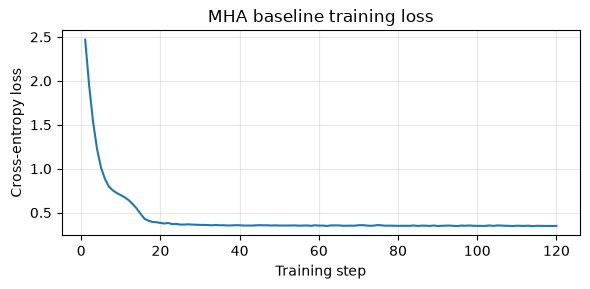

In [4]:
torch.manual_seed(42)
model = TinyLlama(len(words), dim=MODEL_DIM, heads=MODEL_HEADS, layers=MODEL_LAYERS,
                  attention_factory=MHAttention).to(device)
mha_losses = train_model(model, 'MHA baseline')

## 2. Prefill, decode и измерения
Без кэша каждый шаг пересчитывает весь префикс; с кэшем после prefill подаётся только новый токен. Сравниваем одинаковые веса и число новых токенов, с прогревом и повторными измерениями.

`seconds` — время всей генерации; `kv_bytes` — сохранённые K/V, не вся память GPU. Кэш добавляет постоянное хранение; общая пиковая память зависит также от временных матриц внимания.

`prefill_ms` включает первый проход и выбор первого токена; `decode_ms` — оставшуюся генерацию. Используем эти же функции для MHA, MQA и GQA. Полный KV-кэш уже реализован на MHA.

По умолчанию промпт содержит **2048 токенов**, генерируем 48 новых. Названия в таблице: `Original model (MHA, no KV cache)` — исходная модель без кэша; `Original model + full KV cache` — та же модель с кэшем. Далее добавим MQA и GQA с полным кэшем.

**Вопрос:** почему сохраняются исторические K/V, но не Q?

In [5]:
measure_model(model, 'MHA', include_no_cache=True)
full_mha = next(row for row in comparison_rows if row['architecture']=='MHA' and row['mode']=='full cache')
stored_tokens = prompt.shape[1]+NEW_TOKENS-1
expected_bytes = 2*prompt.shape[0]*model.layers*model.heads*stored_tokens*(model.dim//model.heads)*4
assert full_mha['kv_bytes']==expected_bytes
print('Full MHA cache matches the size formula.')

Full-cache logits match recomputation.
MHA continuation: alice likes red . alice likes red . alice likes red . alice likes red . alice likes red . alice likes red . alice likes red . alice likes red . alice likes red . alice likes red . alice likes red . alice likes red .
MHA continuation: alice likes red . alice likes red . alice likes red . alice likes red . alice likes red . alice likes red . alice likes red . alice likes red . alice likes red . alice likes red . alice likes red . alice likes red .
Prompt: 2048 tokens; generated: 48; repeats: 3; batch: 1
inference setup                               prefill_ms  decode_ms  total_ms  KV_KiB
Original model (MHA, no KV cache)                  95.91    4788.85   4888.07     0.00
Original model + full KV cache                     97.40      65.67    161.48  2095.00
Full MHA cache matches the size formula.


## 3. MQA: полный пример
**Статья:** [Fast Transformer Decoding: One Write-Head is All You Need](https://arxiv.org/abs/1911.02150).

MQA сохраняет разные Q, но использует одну общую голову K/V: `H_Q=4`, `H_KV=1`, `head_dim=MODEL_DIM/4` (64 на GPU, 16 на CPU). Q имеет форму `[B,4,T,head_dim]`, K/V — `[B,1,T,head_dim]`.

Код ниже полный. При вычислении внимания единственная KV-голова распространяется на все Q, но в кэше сохраняется только одна голова. При одинаковом числе токенов KV занимает 1/4 исходного MHA. Обучаем MQA отдельно на тех же данных, добавляем MQA + full KV cache в таблицу к исходным двум режимам. Ускорение нужно измерить.

In [6]:
"""Complete teaching implementation of multi-query attention."""
class MQAttention(nn.Module):
    def __init__(self, dim, heads=4):
        super().__init__()
        if dim % heads:
            raise ValueError('dim must be divisible by heads')
        self.heads, self.kv_heads, self.head_dim = heads, 1, dim//heads
        self.qkv = nn.Linear(dim, dim+2*self.head_dim, bias=False)
        self.out = nn.Linear(dim, dim, bias=False)

    def forward(self, x, old=None, use_cache=False):
        b, t, d = x.shape
        q,k,v = self.qkv(x).split([d,self.head_dim,self.head_dim],dim=-1)
        q = q.view(b,t,self.heads,self.head_dim).transpose(1,2)
        k = k.view(b,t,1,self.head_dim).transpose(1,2)
        v = v.view(b,t,1,self.head_dim).transpose(1,2)
        previous = 0 if old is None else old[0].shape[2]
        if old is not None:
            k, v = torch.cat((old[0],k),2), torch.cat((old[1],v),2)
        # Store just one KV head, before applying RoPE.
        cache = (k,v) if use_cache else None
        q, rotated_k = rope(q,start_pos=previous), rope(k)
        # All query heads read the same K/V directly, without repeating their data.
        scores = torch.einsum('bhtd,bsd->bhts',q,rotated_k[:,0])/math.sqrt(self.head_dim)
        if t > 1:
            key_pos = torch.arange(k.shape[2],device=x.device)
            query_pos = torch.arange(previous,previous+t,device=x.device)
            allowed = key_pos[None,:]<=query_pos[:,None]
            scores = scores.masked_fill(~allowed[None,None],float('-inf'))
        attention = scores.softmax(-1)
        y = torch.einsum('bhts,bsd->bhtd',attention,v[:,0])
        y = y.transpose(1,2).contiguous().view(b,t,d)
        return self.out(y),cache

MQA final training loss: 0.349
Full-cache logits match recomputation.
MQA continuation: bob likes blue . bob likes blue . bob likes blue . bob likes blue . bob likes blue . bob likes blue . bob likes blue . bob likes blue . bob likes blue . bob likes blue . bob likes blue . bob likes blue .
Prompt: 2048 tokens; generated: 48; repeats: 3; batch: 1
inference setup                               prefill_ms  decode_ms  total_ms  KV_KiB
Original model (MHA, no KV cache)                  95.91    4788.85   4888.07     0.00
Original model + full KV cache                     97.40      65.67    161.48  2095.00
MQA + full KV cache                                87.63      40.65    128.28   523.75
MQA stores one KV head; full-cache storage is 1/4 of MHA.


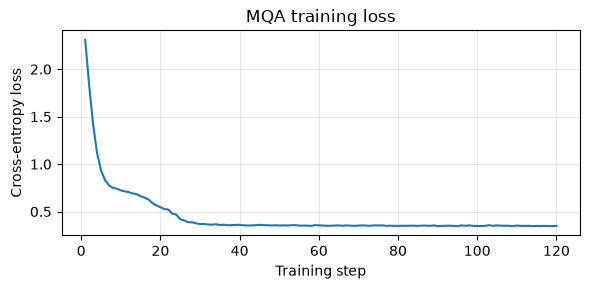

In [7]:
torch.manual_seed(42)
mqa_model = TinyLlama(len(words), dim=MODEL_DIM, heads=MODEL_HEADS, layers=MODEL_LAYERS,
                      attention_factory=MQAttention).to(device)
mqa_losses = train_model(mqa_model, 'MQA')
measure_model(mqa_model, 'MQA')
full_mqa = next(row for row in comparison_rows if row['architecture']=='MQA' and row['mode']=='full cache')
assert full_mqa['kv_bytes']*4==full_mha['kv_bytes']
_, mqa_cache = mqa_model(prompt[:,:4], use_cache=True)
assert all(k.shape[1]==v.shape[1]==1 for k,v in mqa_cache)
print('MQA stores one KV head; full-cache storage is 1/4 of MHA.')

## 4. Упражнение 1: GQA
**Статья:** [GQA: Training Generalized Multi-Query Transformer Models from Multi-Head Checkpoints](https://arxiv.org/abs/2305.13245).

Сценарий: `H_Q=4`, `H_KV=2`, `head_dim=MODEL_DIM/4`. Q0/Q1 используют KV0; Q2/Q3 используют KV1. Выполните TODO в `GQAttention.forward`, сравнив исходный MHA и полный MQA из раздела 3.

- Q: `[B,4,T,head_dim]`; K/V: `[B,2,T,head_dim]`. Общая проекция выдаёт `MODEL_DIM + 2*H_KV*head_dim` значений; разделите её на Q/K/V.
- Добавьте прошлые K/V; в сохранённом кэше должны остаться **2 KV-головы**.
- Примените RoPE как в MHA: `rope(q, start_pos=previous)` и `rope(k)`. Сгруппируйте Q в `[B,2,2,T,head_dim]`; вычислите scores через `einsum('bhgtd,bhsd->bhgts', ...)`, а выход — через `einsum('bhgts,bhsd->bhgtd', ...)`. Так K/V не копируются на каждую Q-голову.
- Верните выход `[B,T,MODEL_DIM]` и пару не повёрнутых K/V либо `None`, как у MHA.

Проверки и обучение ниже предоставлены. С одинаковыми слоями, dtype и числом токенов KV-кэш GQA должен занимать половину MHA. GQA — другая архитектура: обучаем её отдельно на тех же данных с тем же числом шагов, а не просто переключаем головы у обученного MHA. Скорость и качество следует измерить.

In [8]:
"""Student exercise: implement grouped-query attention forward."""
class GQAttention(nn.Module):
    def __init__(self, dim, heads=4, kv_heads=2):
        super().__init__()
        if dim % heads or heads % kv_heads:
            raise ValueError('dim must divide into heads; heads must divide into KV groups')
        self.heads, self.kv_heads, self.head_dim = heads, kv_heads, dim//heads
        self.qkv = nn.Linear(dim, dim+2*kv_heads*self.head_dim, bias=False)
        self.out = nn.Linear(dim, dim, bias=False)

    def forward(self, x, old=None, use_cache=False):
        # TODO: split the fused Q/K/V projection using query heads vs KV heads.
        # TODO: append old unrotated K/V and keep only kv_heads in the cache.
        # TODO: group Q as [B, KV heads, queries per KV, T, head_dim].
        # TODO: apply cache-relative RoPE; contract with compact K/V using einsum.
        # TODO: causal attention and output projection; return (output, cache).
        return None

In [9]:
probe = GQAttention(64, heads=4, kv_heads=2).to(device)
trial = probe(torch.randn(1, 3, 64, device=device), use_cache=True)
if trial is None:
    print('TODO: implement GQAttention.forward; training and comparison are skipped.')
else:
    output, cache = trial
    assert output.shape==(1,3,64)
    assert cache[0].shape==cache[1].shape==(1,2,3,16)
    # With as many KV heads as Q heads, GQA must reproduce ordinary MHA.
    mha_check = MHAttention(64,4).to(device)
    gqa_check = GQAttention(64,4,4).to(device)
    with torch.no_grad():
        gqa_check.qkv.weight.copy_(mha_check.qkv.weight)
        gqa_check.out.weight.copy_(mha_check.out.weight)
    x = torch.randn(2,5,64,device=device)
    torch.testing.assert_close(mha_check(x)[0], gqa_check(x)[0], rtol=1e-4, atol=2e-5)
    # Controlled values verify that Q0/Q1 share KV0 and Q2/Q3 share KV1.
    grouped = GQAttention(64,4,2).to(device)
    with torch.no_grad():
        grouped.qkv.weight.zero_()
        v_start = 64+2*16  # Q output size + K output size
        grouped.qkv.weight[v_start:v_start+16].fill_(1/64)
        grouped.qkv.weight[v_start+16:].fill_(2/64)
        grouped.out.weight.copy_(torch.eye(64,device=device))
        actual,_ = grouped(torch.ones(1,3,64,device=device))
    wanted = torch.tensor([1.]*32+[2.]*32,device=device).view(1,1,64).expand(1,3,64)
    torch.testing.assert_close(actual,wanted)
    torch.manual_seed(42)
    gqa_model = TinyLlama(len(words), dim=MODEL_DIM, heads=MODEL_HEADS, layers=MODEL_LAYERS,
                          attention_factory=lambda dim,heads: GQAttention(dim,heads,2)).to(device)
    gqa_losses = train_model(gqa_model,'GQA')
    measure_model(gqa_model,'GQA')
    full_gqa = next(row for row in comparison_rows if row['architecture']=='GQA' and row['mode']=='full cache')
    assert full_gqa['kv_bytes']*2==full_mha['kv_bytes']
    assert full_gqa['kv_bytes']==full_mqa['kv_bytes']*2
    print('GQA full-cache storage is half of MHA at the same token count.')

TODO: implement GQAttention.forward; training and comparison are skipped.


## 5. Упражнение 2: StreamingLLM
**Статья:** [Efficient Streaming Language Models with Attention Sinks](https://arxiv.org/abs/2309.17453). [Код авторов](https://github.com/mit-han-lab/streaming-llm).
Используйте исходную обученную MHA из раздела 1: это упражнение можно выполнить независимо от GQA.

**A. `trim_cache(cache, budget, sink_tokens, reserve)`** возвращает список пар `(K, V)` либо `None` при отсутствии кэша.

- `budget` — максимум токенов; `sink_tokens` — число начальных токенов; `reserve` — место для новых токенов.
- Перед одним новым токеном оставьте не более `budget−1` старых позиций. Если место уже есть, ничего не удаляйте; иначе оставьте начало и последние позиции.
- Ось токенов — 2. K/V и все слои должны сохранять одинаковые позиции. Создавайте компактные тензоры: view может удерживать большое исходное хранилище.

**B. `stream_generate`** обрабатывает промпт по одному токену, освобождая место перед каждым вызовом. Передавайте только новый токен и кэш. После промпта выполните жадную генерацию; первый новый токен выбирается из logits последнего токена промпта.

Верните словарь: `ids` — промпт с продолжением; `cache` — итоговый кэш; `seconds` — полное время с синхронизацией CUDA; `kv_bytes` — итоговый размер K/V.

**Подсказка о позициях:** модель уже хранит K до RoPE и перенумеровывает позиции внутри кэша. Не подставляйте глобальный номер токена после удаления. Только обрезать уже повёрнутые K недостаточно.

Используйте `torch.inference_mode()`. Решение напишите самостоятельно.

In [10]:
def trim_cache(cache, budget=32, sink_tokens=4, reserve=1):
    """Keep initial + recent slots, leaving reserve free slots within budget."""
    if not (0 <= reserve < budget and 0 <= sink_tokens <= budget-reserve):
        raise ValueError("Require 0 <= reserve < budget and 0 <= sink_tokens <= budget-reserve")
    # TODO: select K/V positions in every layer.
    return None

@torch.inference_mode()
def stream_generate(prompt, new_tokens=48, budget=32, sink_tokens=4):
    """Return ids, cache, seconds and kv_bytes; process prompt incrementally."""
    # TODO: implement prompt processing, cache eviction, decoding and timing.
    return None

### Проверки и сравнение
После TODO сравните полный кэш, окно (`sink_tokens=0`) и StreamingLLM (`sink_tokens=4`) при одном бюджете. Измените бюджет и длину генерации; сравните время, размер кэша и текст.

Полный FP32-кэш: `2 × batch × layers × heads × tokens × head_dim × 4` байт. Ограниченный кэш содержит не более `budget` токенов.

Здесь StreamingLLM обрабатывает промпт последовательно, а полный кэш использует общий prefill: время включает это различие. Маленькая локальная грамматика может не проявлять attention sinks больших предобученных моделей. Не требуется обязательное превосходство StreamingLLM.

Кратко объясните результаты и почему удалённые сведения больше недоступны.

In [11]:
test_k = torch.arange(10, device=device).view(1, 1, 10, 1).float()
test_cache = [(test_k, test_k+100)]
selected = trim_cache(test_cache, budget=5, sink_tokens=2, reserve=0)
if selected is None:
    print("TODO: implement trim_cache to run the checks.")
else:
    assert selected[0][0].flatten().tolist() == [0, 1, 7, 8, 9]
    assert selected[0][1].flatten().tolist() == [100, 101, 107, 108, 109]
    reserved = trim_cache(test_cache, budget=5, sink_tokens=2, reserve=1)
    assert reserved[0][0].flatten().tolist() == [0, 1, 8, 9]
    recent = trim_cache(test_cache, budget=3, sink_tokens=0, reserve=1)
    assert recent[0][0].flatten().tolist() == [8, 9]
    assert trim_cache(None, budget=5) is None
    print("Cache selection checks passed.")

completed = stream_generate(encode("alice likes"), new_tokens=4, budget=32)
if completed is None:
    print("TODO: implement stream_generate to run the experiment.")
else:
    expected = baseline_generate(encode("alice likes"), new_tokens=4)
    assert torch.equal(completed["ids"], expected["ids"])
    base = baseline_generate(prompt)
    print(f"full cache: {base['seconds']:.4f} s; {base['kv_bytes']/1024:.1f} KiB")
    for sinks in [0, 4]:
        stream_generate(prompt, new_tokens=8, budget=32, sink_tokens=sinks)
        runs = [stream_generate(prompt, budget=32, sink_tokens=sinks) for _ in range(3)]
        elapsed = sorted(r["seconds"] for r in runs)[1]
        result = runs[-1]
        assert result["ids"].shape[1] == prompt.shape[1]+48
        assert all(k.shape[2] <= 32 and v.shape[2] <= 32 for k,v in result["cache"])
        print(f"sinks={sinks}: {elapsed:.4f} s; {result['kv_bytes']/1024:.1f} KiB")
        print(decode(result["ids"][0, prompt.shape[1]:]))
        comparison_rows.append({'architecture':'MHA','mode':'window' if sinks==0 else 'Streaming',
                                'seconds':elapsed,'kv_bytes':result['kv_bytes']})
    show_comparison()

TODO: implement trim_cache to run the checks.
TODO: implement stream_generate to run the experiment.
